# Special Events Data Exploration
Explore each available file in terms of columns available and how full the data is.

In [1]:
import pandas as pd
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from functools import lru_cache
import numpy as np

In [2]:
project_root = next(
                    path
                    for path in (Path.cwd(), *Path.cwd().parents)
                    if (path / "src" / "msc_thesis").is_dir()
                )
sys.path.insert(0, str(project_root / "src"))

events_dir = project_root / "data" /"raw" / "events"

## Facebook Events

In [3]:
facebook_events_df = pd.read_csv(events_dir / "facebook_events.csv")
facebook_events_df.head(5)

,id,start,end,n_attending,n_declined,n_maybe,n_interested,owner_id,event_category,place_latitude,...,place_name,place_city,place_country,place_state,place_street,place_zip,OG_n_attending,n_political_attending,political_attendees,percent_political
0,149546672171110,2016-11-05T20:00:00+0100,2016-11-05T23:00:00+0100,17,0,20,20,af9c2f0f93c117b94887cb5245127554a01442f5b92686...,NaN,55.67610,...,Copenhagen,Copenhagen,Denmark,NaN,NaN,NaN,17,0,set(),0.0
1,498195710570724,2017-05-04T17:45:00+0200,2017-05-04T18:25:00+0200,27,0,59,59,72240da246b1a06f28dcc06b40e328ea52393e76c16591...,NaN,55.67449,...,"Nationalmuseet (aktiviteter, tilbud m.m.)",København,Denmark,NaN,Ny Vestergade 10,1220,27,0,set(),0.0
2,207324133080663,2017-03-15T17:00:00+0100,2017-03-15T19:00:00+0100,5,0,24,24,0f8177f30c70d56b6338599f89017c5e08361a3a7ba80d...,NaN,55.68042,...,Bitlab - Copenhagen Business School,Frederiksberg,Denmark,NaN,Howitzvej 60,2000,5,0,set(),0.0
3,144194456022010,2016-09-09T14:00:00+0200,2016-09-10T03:00:00+0200,440,0,163,163,43e14752ef8cb4130b27de113bd527d2d66904cd4428b5...,NaN,55.70280,...,FreBAR,København,Denmark,NaN,Universitetsparken 2,2100,440,0,set(),0.0
4,255578924899334,2017-04-04T18:00:00+0200,2017-04-04T21:15:00+0200,15,0,52,52,ae5b49af7c4865e6f44df48df5659cb772ed54c6903392...,NaN,55.65943,...,Casa Latinoamericana Denmark,Valby,Denmark,NaN,Høffdingsvej 10,2500,15,0,set(),0.0


In [4]:
print(facebook_events_df.columns)

# Select only relevant columns
relevant_columns = ['id', 'start', 'end', 'n_attending', 'n_declined', 'n_maybe',
       'n_interested', 'event_category', 'place_latitude',
       'place_longitude', 'place_name']
relevant_columns += [column for column in ["event_name"] if column in facebook_events_df.columns]
facebook_events_df = facebook_events_df[relevant_columns].copy()

Index(['id', 'start', 'end', 'n_attending', 'n_declined', 'n_maybe',
       'n_interested', 'owner_id', 'event_category', 'place_latitude',
       'place_longitude', 'place_name', 'place_city', 'place_country',
       'place_state', 'place_street', 'place_zip', 'OG_n_attending',
       'n_political_attending', 'political_attendees', 'percent_political'],
      dtype='str')


<Axes: title={'center': 'Event Category Distribution'}, xlabel='event_category'>

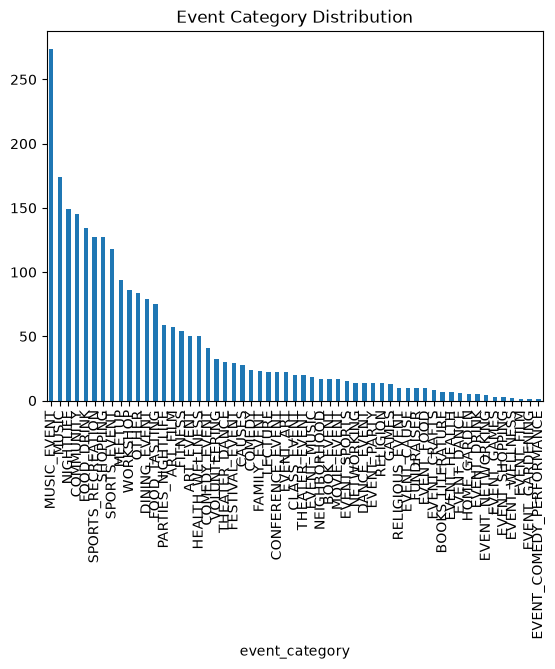

In [5]:
facebook_events_df['event_category'].value_counts().plot(kind='bar', title='Event Category Distribution')

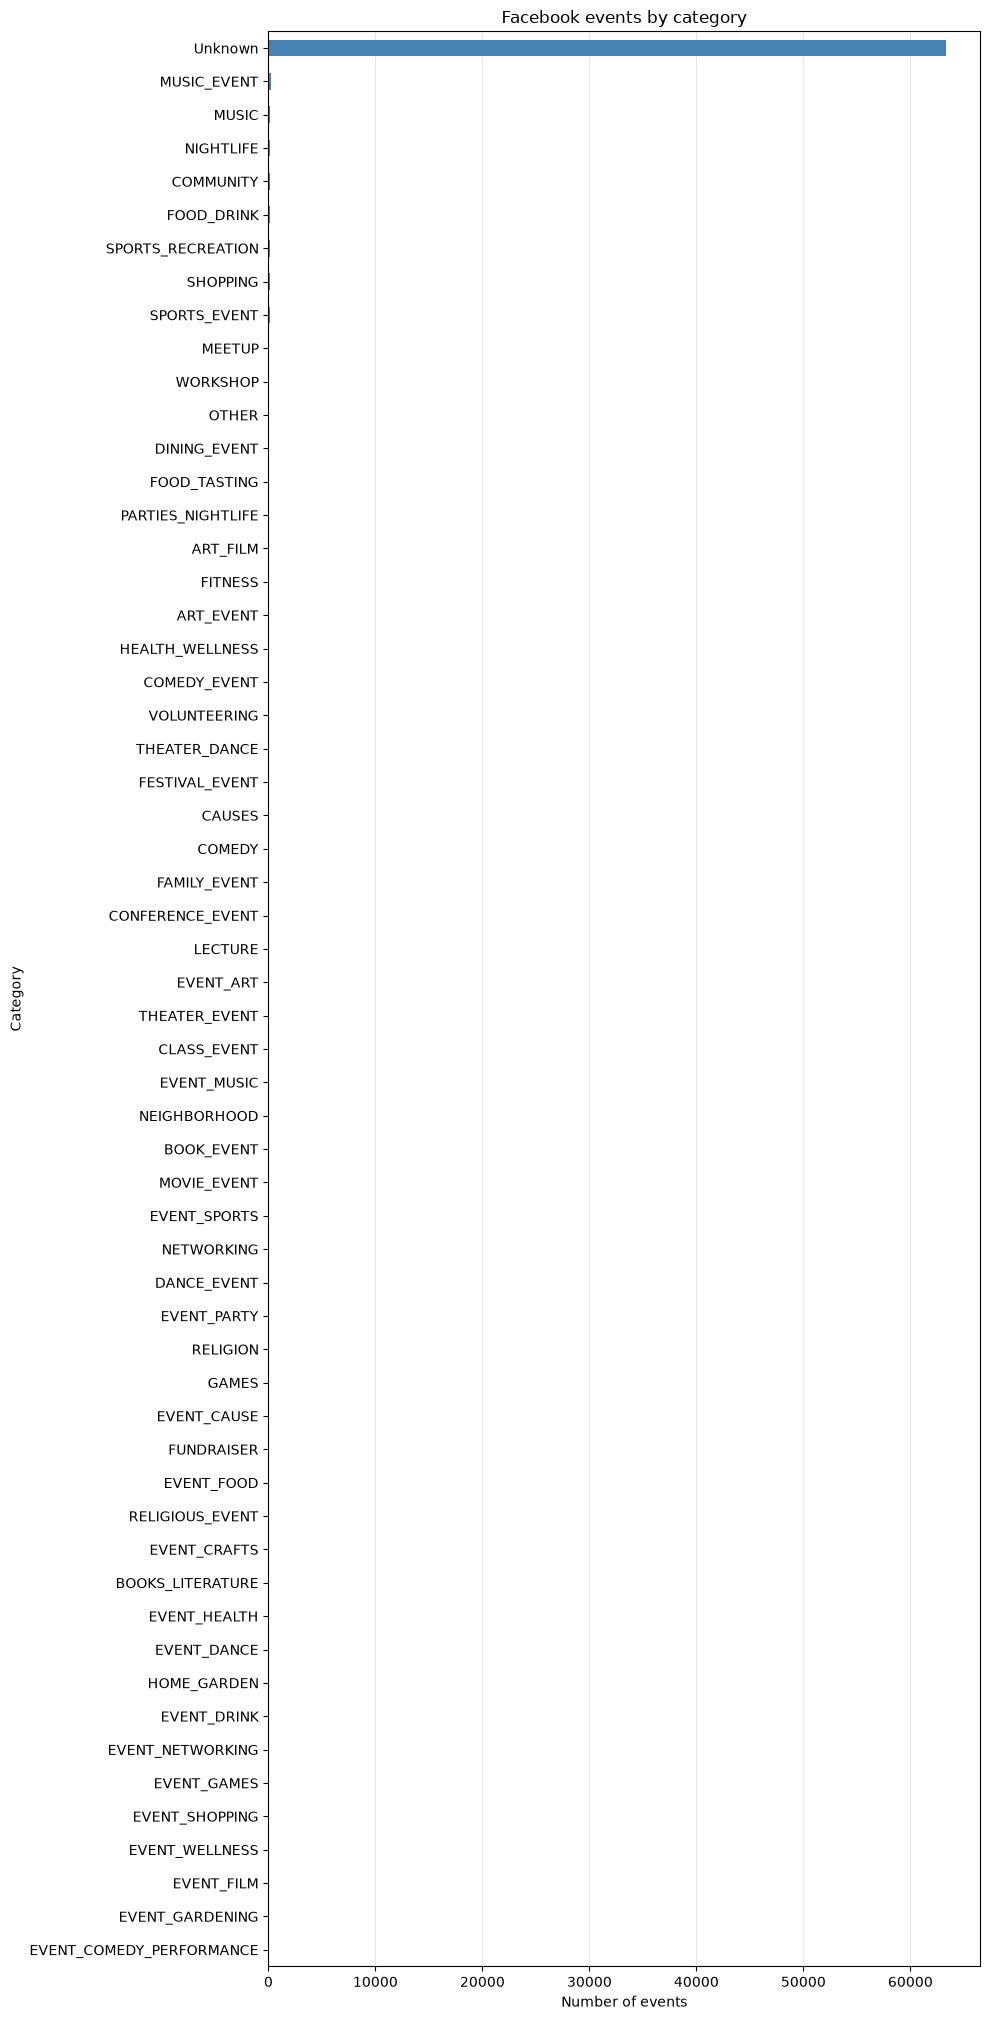

In [6]:
# Plot the number of events per category
category_counts = (
    facebook_events_df["event_category"]
    .fillna("Unknown")
    .replace(r"^\s*$", "Unknown", regex=True)
    .value_counts()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, max(4, len(category_counts) * 0.35)))
if category_counts.empty:
    ax.text(0.5, 0.5, "No events available", ha="center", va="center", transform=ax.transAxes)
else:
    category_counts.plot.barh(ax=ax, color="steelblue")
ax.set(title="Facebook events by category", xlabel="Number of events", ylabel="Category")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

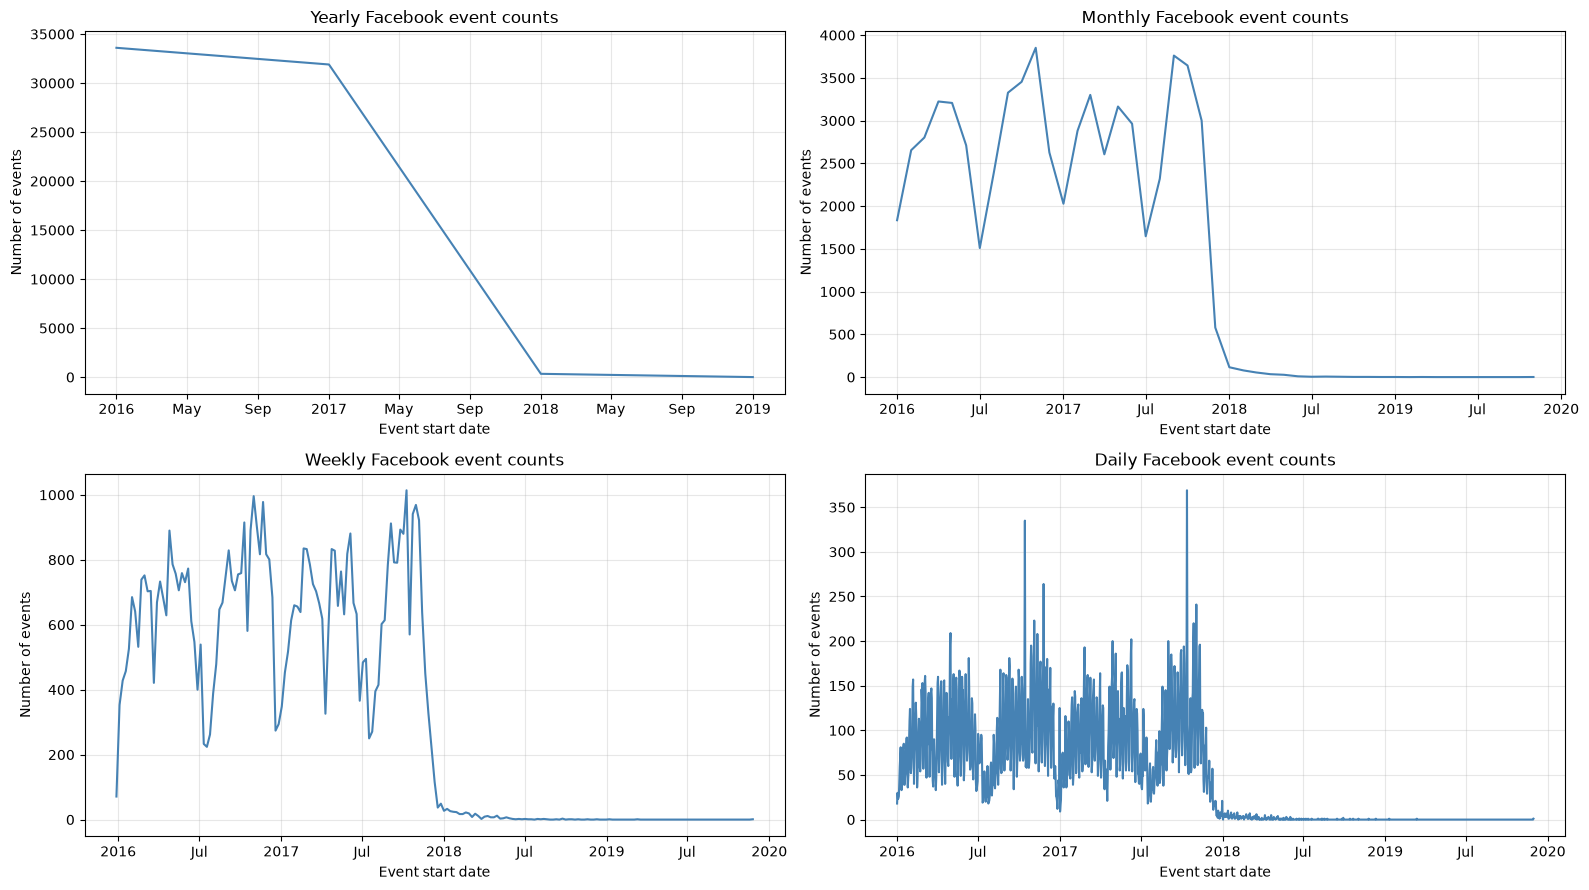

In [7]:
# Plot the number of events per time (yearly, monthly, weekly, daily)
# Parse mixed UTC offsets, then group by the local event date in Copenhagen.
event_starts = pd.to_datetime(
    facebook_events_df["start"], format="mixed", errors="coerce", utc=True
).dt.tz_convert("Europe/Copenhagen")
missing_dates = event_starts.isna().sum()
if missing_dates:
    print(f"Excluded {missing_dates:,} events with missing or invalid start dates from the time plots.")

events_over_time = pd.Series(1, index=pd.DatetimeIndex(event_starts.dropna())).sort_index()
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (label, frequency) in zip(
    axes.flat,
    [("Yearly", "YS"), ("Monthly", "MS"), ("Weekly", "W-MON"), ("Daily", "D")],
):
    if events_over_time.empty:
        ax.text(0.5, 0.5, "No valid start dates", ha="center", va="center", transform=ax.transAxes)
    else:
        # Label weeks by their Monday start; include zero-count periods.
        counts = events_over_time.resample(frequency, label="left", closed="left").sum()
        ax.plot(counts.index, counts.values, color="steelblue", linewidth=1.5)
        locator = mdates.AutoDateLocator(tz=event_starts.dt.tz)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=event_starts.dt.tz))
    ax.set(title=f"{label} Facebook event counts", xlabel="Event start date", ylabel="Number of events")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Calculate Estimated Attendance 

_Assumptions_

These rates are illustrative and not fitted to actual attendance.

- 90% of "attending" people attend.
- 30% of "maybe" people attend.
- 5% of "interested" people attend.
- A multiplier of 1.5 adds 50% for attendees who did not respond on Facebook.
- Response groups are assumed to be distinct; declined responses contribute zero.
- The same parameters apply to all events, without a venue-capacity cap.
- Missing or invalid counts leave the estimate unknown rather than assuming zero.
- Zero responses yield zero; estimates can also be lower than `n_attending`.
- Calibrate these assumptions against observed attendance before relying on them.

> Data caveat: `n_maybe` and `n_interested` appear identical in the current CSV. Verify that they are distinct groups; otherwise this formula can double-count people.


In [8]:
# Get estimated attendance for each event, using 'n_attending', 'n_maybe', 'n_interested'

attendance_rates = pd.Series({
    "n_attending": 0.90,
    "n_maybe": 0.30,
    "n_interested": 0.05,
})
attendance_uplift = 1.5

attendance_counts = facebook_events_df[attendance_rates.index].apply(
    pd.to_numeric, errors="coerce"
)
attendance_counts = attendance_counts.where(
    attendance_counts.ge(0) & attendance_counts.lt(float("inf"))
)

if (
    not attendance_counts.empty
    and attendance_counts[["n_maybe", "n_interested"]].notna().all().all()
    and attendance_counts["n_maybe"].eq(attendance_counts["n_interested"]).all()
):
    print("Warning: n_maybe and n_interested are identical; verify that they describe separate groups.")

# Keep fractional values because these represent expected attendance.
facebook_events_df["estimated_attendance"] = (
    attendance_counts.mul(attendance_rates)
    .sum(axis=1, min_count=3)
    .mul(attendance_uplift)
    .round().astype("Int64")
)

display(facebook_events_df[
    ["id", "n_attending", "n_maybe", "n_interested", "estimated_attendance"]
].head())


,id,n_attending,n_maybe,n_interested,estimated_attendance
0,149546672171110,17,20,20,33
1,498195710570724,27,59,59,67
2,207324133080663,5,24,24,19
3,144194456022010,440,163,163,680
4,255578924899334,15,52,52,48


## Setlistfm Data

In [9]:
merge_files = False

In [10]:
if merge_files:
    # Get combined setlistfm data (files starting with setlistfm)
    setlistfm_files = [f for f in os.listdir(events_dir) if f.startswith("setlistfm") and f.endswith(".csv")]
    setlistfm_dfs = []
    for file in setlistfm_files:
        df = pd.read_csv(events_dir / file)
        setlistfm_dfs.append(df)
    setlistfm_events_df = pd.concat(setlistfm_dfs, ignore_index=True)
    setlistfm_events_df.head(5)

    # Make 'event_date' a date type and sort by it
    setlistfm_events_df['event_date'] = pd.to_datetime(setlistfm_events_df['event_date'], errors='coerce').dt.date
    setlistfm_events_df = setlistfm_events_df.sort_values(by='event_date', ascending=True)
    setlistfm_events_df.head(5)

    # Write to CSV
    output_path = events_dir / "setlistfm_events.csv"
    setlistfm_events_df.to_csv(output_path, index=False)
else:
    print("Skipping Setlist.fm merge because merge_files is False.")


Skipping Setlist.fm merge because merge_files is False.


### Analysis
Data was provided to an AI model that added latitude and longitude where missing, and some of start time and end time, as well as estimated attendance was filled. 

In [11]:
setlistfm_events_df = pd.read_csv(events_dir / "setlistfm_events_final.csv")
setlistfm_events_df.head(5)

,event_name,event_date,start_time,end_time,venue_name,latitude,longitude,estimated_attendance
0,First Hate @ DR Koncerthuset,2017-01-06,NaN,NaN,DR Koncerthuset,55.657761,12.588894,NaN
1,Perry MacLeod Jensen @ Bryggekælderen,2017-01-06,NaN,NaN,Bryggekælderen,NaN,NaN,NaN
2,Geoff Tate @ High Voltage,2017-01-06,NaN,NaN,High Voltage,NaN,NaN,NaN
3,Hexis @ KB18,2017-01-06,NaN,NaN,KB18,NaN,NaN,NaN
4,Svartmálm @ Pumpehuset,2017-01-07,NaN,NaN,Pumpehuset,55.677125,12.565194,NaN


## General Cph Events

In [12]:
general_events_df = pd.read_csv(events_dir / "events_cph_2017_2022.csv")
general_events_df.head(5)

,date,end_date,start_local,venue,category,event_name,attendance,attendance_type,capacity,sold_out,covid_window,status,nearest_stations,source_file,source_url
0,2017-02-03,2017-02-03,NaN,Royal Arena,arena_music,METALLICA,NaN,NaN,17000,yes,NaN,listed_until_shortly_before,Ørestad,royal_arena.csv,https://web.archive.org/web/*/royalarena.dk/ev...
1,2017-02-05,2017-02-05,NaN,Royal Arena,arena_music,METALLICA,NaN,NaN,17000,yes,NaN,postponed_to_2017-09-02; royalarena.dk/event/m...,Ørestad,royal_arena.csv,https://web.archive.org/web/*/royalarena.dk/ev...
2,2017-02-07,2017-02-07,NaN,Royal Arena,arena_music,METALLICA,NaN,NaN,17000,yes,NaN,listed_until_shortly_before,Ørestad,royal_arena.csv,https://web.archive.org/web/*/royalarena.dk/ev...
3,2017-02-09,2017-02-09,NaN,Royal Arena,arena_music,METALLICA,NaN,NaN,17000,yes,NaN,listed_until_shortly_before,Ørestad,royal_arena.csv,https://web.archive.org/web/*/royalarena.dk/ev...
4,2017-02-17,2017-02-17,18:00,Right to Dream Park (Farum),football_superliga,FC Nordsjælland - Lyngby BK (Superliga),2688.0,spectators,NaN,NaN,NaN,NaN,Farum,football_superliga.csv,https://superstats.dk/program?season=2017


In [13]:
print(general_events_df.columns)

Index(['date', 'end_date', 'start_local', 'venue', 'category', 'event_name',
       'attendance', 'attendance_type', 'capacity', 'sold_out', 'covid_window',
       'status', 'nearest_stations', 'source_file', 'source_url'],
      dtype='str')


In [14]:
# Get only relevant columns from general events data
relevant_columns_general = ['date', 'end_date', 'start_local', 'venue', 'category', 'event_name', 'attendance', 'nearest_stations']
relevant_columns_general += [
    column for column in ["id", "latitude", "longitude", "end_time"]
    if column in general_events_df.columns
]
general_events_df = general_events_df[relevant_columns_general].copy()

# Combine special event data

Combine Facebook, Setlist.fm, and general Copenhagen events into one dataframe using the following columns:

`event_id`, `start_date`, `end_date`, `start_time`, `end_time`, `venue_name`, `latitude`, `longitude`, `estimated_attendance`, `event_category`, `nearest_stations`, `source`.

### Event identifier

Use the event name as `event_id` when a nonempty name is available. Trim surrounding whitespace; treat blank names as missing. If no name is available, use the original source ID as a string (Facebook `id` or Setlist.fm `setlist_id`). Do not add a source prefix or create a separate `event_name` column. If both name and source ID are missing, leave `event_id` missing for review.

An event name can occur on different dates or at different venues, so `event_id` is not necessarily unique. Do not deduplicate on this field alone; compare dates, venues, and sources as well.

### Dates and times

| Column | Meaning |
| --- | --- |
| `start_date` | Calendar date on which the event starts, in `YYYY-MM-DD` format. |
| `end_date` | Calendar date on which the event ends, in `YYYY-MM-DD` format; missing if unknown. |
| `start_time` | Local clock time at which the event starts, in `HH:MM:SS` format; missing if unknown. |
| `end_time` | Local clock time at which the event ends, in `HH:MM:SS` format; missing if unknown. |

Dates and clock times are stored separately. Convert timestamps with explicit timezone offsets to `Europe/Copenhagen` before extracting these fields. Clock times without an offset are assumed to be Copenhagen local time. Keep unavailable values missing rather than replacing them with midnight or an assumed duration.

| Available information | Assignment |
| --- | --- |
| Exact start and end timestamps | Extract the local start date/time and end date/time into all four fields. |
| Start date only | Set `start_date`; leave `end_date`, `start_time`, and `end_time` missing. |
| Start and end dates only | Preserve both dates; leave both times missing. |
| Start date and exact start time, no end information | Set `start_date` and `start_time`; leave both end fields missing. |
| Exact start and an end date, no end time | Set `start_date`, `start_time`, and `end_date`; leave `end_time` missing. |
| Start date and an exact end timestamp, no start time | Set `start_date`, `end_date`, and `end_time`; leave `start_time` missing. |
| Overnight or multi-day event with explicit dates | Preserve the different start and end dates and any available times. |
| End clock time without an end date | Preserve `end_time`, but leave `end_date` missing. An earlier end clock time may indicate an overnight event; do not assume the date. |

For example, a Facebook event starting at `2016-09-09 14:00` and ending at `2016-09-10 03:00` becomes `start_date = 2016-09-09`, `end_date = 2016-09-10`, `start_time = 14:00:00`, and `end_time = 03:00:00`.

Do not infer that an event ends on its start date when the source provides no end date. Flag invalid dates, an end date before the start date, or an end time before the start time on an explicitly stated same-day event. Review ambiguous or nonexistent local times around daylight-saving changes before constructing timestamps for analysis.

### Source mappings

- **Facebook:** use the event name if supplied, otherwise `id`. Split `start` and `end` into local dates and times. Map `place_name`, `place_latitude`, and `place_longitude` to the venue fields, and retain the calculated integer `estimated_attendance`.
- **Setlist.fm:** use `event_name` when available, otherwise `setlist_id`. Map `event_date` to `start_date` and retain any supplied clock times. Leave `end_date` missing unless an explicit end date is available. Use `music` as the event category; retain `estimated_attendance` from the final Setlist.fm file where available, otherwise leave it missing.
- **General Copenhagen events:** use `event_name`, otherwise a source ID if available. Map `date` to `start_date`, retain `end_date`, and map the `start_local` clock time to `start_time`. Leave `end_time` missing when unavailable. Map `venue`, `category`, `attendance`, and `nearest_stations` into the corresponding fields.

Missing coordinates and attendance remain missing rather than becoming zero. Store attendance as a nullable integer and normalize station values to lists. Date-only records support daily analysis; hourly analysis needs known times or separately documented assumptions. Source records can overlap, so concatenation alone does not establish the number of distinct events. Keep GTFS disruptions separate from the combined event dataframe.


### Transform each source to the common schema

The later workflow standardizes the raw event records into one consistent table:

- merges Facebook, Setlist.fm, and general Copenhagen events into a single event dataframe
- cleans text values by lowercasing, trimming, and removing extra whitespace
- normalizes dates, times, venue names, categories, and attendance into the same schema
- flags missing or inconsistent dates/times for review instead of forcing assumptions
- standardizes station lists and venue coordinates for downstream matching
- adds nearest GTFS stops based on valid coordinates
- keeps GTFS disruption data separate from the combined event dataset

In short: it converts multiple messy source formats into one comparable event table with consistent fields and location context.

In [15]:
EVENT_COLUMNS = [
    "event_id", "start_date", "end_date", "start_time", "end_time",
    "venue_name", "latitude", "longitude", "estimated_attendance",
    "event_category", "nearest_stations", "source",
]


def source_column(df, name):
    """Return an optional column without replacing missing values with zero."""
    return df[name] if name in df else pd.Series(pd.NA, index=df.index)


def text_column(values):
    return (
        pd.Series(values, copy=False)
        .astype("string")
        .str.normalize("NFKC")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.casefold()
        .replace("", pd.NA)
    )


def event_identifier(df, id_column):
    names = text_column(source_column(df, "event_name"))
    return names.fillna(text_column(source_column(df, id_column)))


def date_column(values):
    dates = pd.to_datetime(values, format="mixed", errors="coerce")
    return dates.dt.strftime("%Y-%m-%d").astype("string")


def time_column(values):
    clocks = text_column(values)
    # Accept HH:MM or HH:MM:SS; reject invalid clock times.
    clocks = clocks.where(clocks.str.fullmatch(r"\d{1,2}:\d{2}(:\d{2})?", na=False))
    clocks = clocks.where(clocks.str.count(":").eq(2), clocks + ":00")
    parsed = pd.to_datetime(clocks, format="%H:%M:%S", errors="coerce")
    return parsed.dt.strftime("%H:%M:%S").astype("string")


def split_timestamp(values):
    """Convert offset timestamps to Copenhagen; naive values are local."""
    values = text_column(values)
    has_offset = values.str.contains(r"(?:Z|[+-]\d{2}:?\d{2})$", na=False)
    local = pd.Series(pd.NaT, index=values.index, dtype="datetime64[ns, Europe/Copenhagen]")
    local.loc[has_offset] = pd.to_datetime(
        values.loc[has_offset], format="mixed", errors="coerce", utc=True
    ).dt.tz_convert("Europe/Copenhagen")
    local.loc[~has_offset] = pd.to_datetime(
        values.loc[~has_offset], format="mixed", errors="coerce"
    ).dt.tz_localize("Europe/Copenhagen", ambiguous="NaT", nonexistent="NaT")
    dates = local.dt.strftime("%Y-%m-%d").astype("string")
    has_clock = values.str.contains(r"[Tt ]\d{1,2}:\d{2}", na=False)
    clocks = local.dt.strftime("%H:%M:%S").astype("string").where(has_clock)
    return dates, clocks


def integer_attendance(values):
    counts = pd.to_numeric(values, errors="coerce")
    return counts.where(counts.ge(0) & counts.lt(float("inf"))).round().astype("Int64")


def station_list(value):
    if isinstance(value, (list, tuple)):
        return [
            str(station).strip().casefold()
            for station in value
            if pd.notna(station) and str(station).strip()
        ]
    if pd.isna(value) or not str(value).strip():
        return []
    # Source strings use semicolons. Keep commas within station descriptions.
    return [
        station.strip().casefold()
        for station in str(value).split(";")
        if station.strip()
    ]


def standardize_events(df, source):
    """Build the agreed schema while retaining the original source dataframe."""
    result = pd.DataFrame(index=df.index)
    if source == "facebook":
        result["event_id"] = event_identifier(df, "id")
        result["start_date"], result["start_time"] = split_timestamp(source_column(df, "start"))
        result["end_date"], result["end_time"] = split_timestamp(source_column(df, "end"))
        venue, latitude, longitude = "place_name", "place_latitude", "place_longitude"
        attendance, category = "estimated_attendance", "event_category"
    else:
        result["event_id"] = event_identifier(df, "setlist_id" if source == "setlistfm" else "id")
        result["start_date"] = date_column(source_column(df, "event_date" if source == "setlistfm" else "date"))
        result["end_date"] = date_column(source_column(df, "end_date"))
        result["start_time"] = time_column(source_column(df, "start_time" if source == "setlistfm" else "start_local"))
        result["end_time"] = time_column(source_column(df, "end_time"))
        venue, latitude, longitude = "venue_name" if source == "setlistfm" else "venue", "latitude", "longitude"
        attendance, category = ("estimated_attendance", "event_category") if source == "setlistfm" else ("attendance", "category")
    result["venue_name"] = text_column(source_column(df, venue))
    result["latitude"] = pd.to_numeric(source_column(df, latitude), errors="coerce").astype("Float64")
    result["longitude"] = pd.to_numeric(source_column(df, longitude), errors="coerce").astype("Float64")
    result["estimated_attendance"] = integer_attendance(source_column(df, attendance))
    result["event_category"] = text_column(source_column(df, category))
    if source == "setlistfm":
        result["event_category"] = result["event_category"].fillna("music")
    result["nearest_stations"] = source_column(df, "nearest_stations").map(station_list)
    result["source"] = pd.Series(source, index=df.index, dtype="string")
    return result[EVENT_COLUMNS]


In [16]:
# The earlier notebook cells call this dataframe setlistfm_events_df.
setlist_fm_df = setlistfm_events_df
facebook_events_standardized_df = standardize_events(facebook_events_df, "facebook")
general_events_standardized_df = standardize_events(general_events_df, "general_cph")
setlist_fm_standardized_df = standardize_events(setlist_fm_df, "setlistfm")

In [17]:
facebook_events_standardized_df.head()

,event_id,start_date,end_date,start_time,end_time,venue_name,latitude,longitude,estimated_attendance,event_category,nearest_stations,source
0,149546672171110,2016-11-05,2016-11-05,20:00:00,23:00:00,copenhagen,55.6761,12.5683,33,<NA>,[],facebook
1,498195710570724,2017-05-04,2017-05-04,17:45:00,18:25:00,"nationalmuseet (aktiviteter, tilbud m.m.)",55.67449,12.57468,67,<NA>,[],facebook
2,207324133080663,2017-03-15,2017-03-15,17:00:00,19:00:00,bitlab - copenhagen business school,55.68042,12.52476,19,<NA>,[],facebook
3,144194456022010,2016-09-09,2016-09-10,14:00:00,03:00:00,frebar,55.7028,12.56138,680,<NA>,[],facebook
4,255578924899334,2017-04-04,2017-04-04,18:00:00,21:15:00,casa latinoamericana denmark,55.65943,12.50108,48,<NA>,[],facebook


In [18]:
general_events_standardized_df.head()

,event_id,start_date,end_date,start_time,end_time,venue_name,latitude,longitude,estimated_attendance,event_category,nearest_stations,source
0,metallica,2017-02-03,2017-02-03,<NA>,<NA>,royal arena,<NA>,<NA>,<NA>,arena_music,[ørestad],general_cph
1,metallica,2017-02-05,2017-02-05,<NA>,<NA>,royal arena,<NA>,<NA>,<NA>,arena_music,[ørestad],general_cph
2,metallica,2017-02-07,2017-02-07,<NA>,<NA>,royal arena,<NA>,<NA>,<NA>,arena_music,[ørestad],general_cph
3,metallica,2017-02-09,2017-02-09,<NA>,<NA>,royal arena,<NA>,<NA>,<NA>,arena_music,[ørestad],general_cph
4,fc nordsjælland - lyngby bk (superliga),2017-02-17,2017-02-17,18:00:00,<NA>,right to dream park (farum),<NA>,<NA>,2688,football_superliga,[farum],general_cph


In [19]:
setlist_fm_standardized_df.head()

,event_id,start_date,end_date,start_time,end_time,venue_name,latitude,longitude,estimated_attendance,event_category,nearest_stations,source
0,first hate @ dr koncerthuset,2017-01-06,<NA>,<NA>,<NA>,dr koncerthuset,55.657761,12.588894,<NA>,music,[],setlistfm
1,perry macleod jensen @ bryggekælderen,2017-01-06,<NA>,<NA>,<NA>,bryggekælderen,<NA>,<NA>,<NA>,music,[],setlistfm
2,geoff tate @ high voltage,2017-01-06,<NA>,<NA>,<NA>,high voltage,<NA>,<NA>,<NA>,music,[],setlistfm
3,hexis @ kb18,2017-01-06,<NA>,<NA>,<NA>,kb18,<NA>,<NA>,<NA>,music,[],setlistfm
4,svartmálm @ pumpehuset,2017-01-07,<NA>,<NA>,<NA>,pumpehuset,55.677125,12.565194,<NA>,music,[],setlistfm


In [20]:
# Combine standardized records without deduplicating by event_id.
special_events_df = pd.concat(
    [facebook_events_standardized_df, general_events_standardized_df, setlist_fm_standardized_df],
    ignore_index=True,
)

# Flag missing start dates and inconsistent known endpoints for review.
end_before_start = special_events_df["end_date"].lt(special_events_df["start_date"])
same_day = special_events_df["end_date"].eq(special_events_df["start_date"])
time_reversed = same_day & special_events_df["end_time"].lt(special_events_df["start_time"])
events_to_review_df = special_events_df.loc[
    special_events_df["start_date"].isna()
    | (end_before_start | time_reversed).fillna(False)
].copy()
print(f"Combined {len(special_events_df):,} records; {len(events_to_review_df):,} require date/time review.")
display(special_events_df.head())


Combined 74,062 records; 0 require date/time review.


,event_id,start_date,end_date,start_time,end_time,venue_name,latitude,longitude,estimated_attendance,event_category,nearest_stations,source
0,149546672171110,2016-11-05,2016-11-05,20:00:00,23:00:00,copenhagen,55.6761,12.5683,33,<NA>,[],facebook
1,498195710570724,2017-05-04,2017-05-04,17:45:00,18:25:00,"nationalmuseet (aktiviteter, tilbud m.m.)",55.67449,12.57468,67,<NA>,[],facebook
2,207324133080663,2017-03-15,2017-03-15,17:00:00,19:00:00,bitlab - copenhagen business school,55.68042,12.52476,19,<NA>,[],facebook
3,144194456022010,2016-09-09,2016-09-10,14:00:00,03:00:00,frebar,55.7028,12.56138,680,<NA>,[],facebook
4,255578924899334,2017-04-04,2017-04-04,18:00:00,21:15:00,casa latinoamericana denmark,55.65943,12.50108,48,<NA>,[],facebook


In [21]:
# Standardize event categories before counting them.
category_aliases = {
    "book": "books",
    "books_literature": "books",
    "art_film": "art",
    "city_pride_parade": "city_pride",
    "arena_music": "music",
    "concert": "music",
    "arena_comedy": "comedy",
    "comedy_performance": "comedy",
    "sport": "sports",
    "arena_sport": "sports",
    "city_sport": "sports",
    "theater": "theatre",
    "party": "parties_nightlife",
    "nightlife": "parties_nightlife",
    "religious": "religion",
    "cause": "causes",
    "food": "food_drink", 
    "drink": "food_drink",
}

special_events_df["event_category"] = (
    special_events_df["event_category"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"[\s-]+", "_", regex=True)
    .str.replace(r"_+", "_", regex=True)
    .str.replace(r"^event_|_event$", "", regex=True)
    .str.strip("_")
    .replace("", pd.NA)
    .replace(category_aliases)
)

In [22]:
# Keep missing categories visible when analysing category coverage.
category_counts_df = (
    special_events_df["event_category"]
    .value_counts(dropna=False)
    .rename_axis("event_category")
    .reset_index(name="event_count")
)
display(category_counts_df.sort_values(by='event_category'))

,event_category,event_count
50,arena_cid_6,2
54,arena_family,1
22,arena_theatre/entertainment,34
8,art,129
27,books,24
21,causes,38
47,city_culture_night,6
51,city_cycling,2
41,city_festival,12
40,city_marathon,12


In [23]:
# Get values of venue_name where latitude or longitude is null
missing_coords_df = special_events_df[
    special_events_df["latitude"].isna() | special_events_df["longitude"].isna()
][["venue_name", "latitude", "longitude"]].drop_duplicates().sort_values(by="venue_name")

display(missing_coords_df)

# Write to CSV
output_path = events_dir / "missing_venue_locations.csv"
missing_coords_df.to_csv(output_path, index=False)

,venue_name,latitude,longitude
69190,"accord, vesterbrogade",<NA>,<NA>
68926,airport,<NA>,<NA>
72500,alice,<NA>,<NA>
70563,aloë cocktail bar,<NA>,<NA>
68468,asminderød kro,<NA>,<NA>
...,...,...,...
67207,zeppelin bar cafe venue,<NA>,<NA>
67672,zeppelin rock bar,<NA>,<NA>
73083,øresundsparken,<NA>,<NA>
71328,østre gasværk teater,<NA>,<NA>


In [24]:
# Fill missing event coordinates from the reviewed venue lookup.
venue_locations_path = events_dir / "venue_locations.csv"
venue_locations_df = pd.read_csv(venue_locations_path)
required_columns = {"venue_name", "latitude", "longitude"}
missing_columns = required_columns.difference(venue_locations_df.columns)
if missing_columns:
    raise ValueError(f"venue_locations.csv is missing columns: {sorted(missing_columns)}")


def venue_match_key(values):
    return (
        values.astype("string")
        .str.normalize("NFKC")
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .replace("", pd.NA)
    )


for column in ["latitude", "longitude"]:
    venue_locations_df[column] = pd.to_numeric(venue_locations_df[column], errors="coerce")

valid_lookup_coordinates = (
    venue_locations_df["latitude"].between(-90, 90)
    & venue_locations_df["longitude"].between(-180, 180)
)
venue_locations_df["_venue_key"] = venue_match_key(venue_locations_df["venue_name"])
venue_locations_df = (
    venue_locations_df.loc[valid_lookup_coordinates & venue_locations_df["_venue_key"].notna()]
    .drop_duplicates("_venue_key", keep="first")
    .set_index("_venue_key")
)

special_events_df["_venue_key"] = venue_match_key(special_events_df["venue_name"])
latitude_lookup = special_events_df["_venue_key"].map(venue_locations_df["latitude"])
longitude_lookup = special_events_df["_venue_key"].map(venue_locations_df["longitude"])
missing_latitude = special_events_df["latitude"].isna() & latitude_lookup.notna()
missing_longitude = special_events_df["longitude"].isna() & longitude_lookup.notna()
special_events_df["latitude"] = special_events_df["latitude"].fillna(latitude_lookup).astype("Float64")
special_events_df["longitude"] = special_events_df["longitude"].fillna(longitude_lookup).astype("Float64")
special_events_df = special_events_df.drop(columns="_venue_key")

print(
    f"Filled {int(missing_latitude.sum()):,} missing latitude values and "
    f"{int(missing_longitude.sum()):,} missing longitude values from venue_locations.csv."
)


Filled 2,241 missing latitude values and 2,241 missing longitude values from venue_locations.csv.


# Add Nearest Stops

For each event with valid latitude and longitude, this step finds the **five nearest GTFS stops** from `stops.txt`. It ranks stops by Haversine distance, the straight-line distance over the Earth's surface, and records stop IDs, names, and distances in metres. Repeated event coordinates are calculated once and cached.

These distances are not walking or travel distances. Different stop IDs may have the same stop name, for example when platforms are represented separately. Events without valid coordinates receive empty stop-ID and distance lists; any station names supplied by the source are retained. For events with coordinates, the computed GTFS names replace supplied station names.


In [38]:
# Load and validate GTFS stop locations.
stops_path = events_dir / "GTFS" / "stops.txt"
STOP_COUNT = 5
EARTH_RADIUS_M = 6_371_000

gtfs_stops_df = pd.read_csv(
    stops_path,
    usecols=["stop_id", "stop_name", "stop_lat", "stop_lon"],
    dtype={"stop_id": "string", "stop_name": "string"},
)
for coordinate in ["stop_lat", "stop_lon"]:
    gtfs_stops_df[coordinate] = pd.to_numeric(gtfs_stops_df[coordinate], errors="coerce")

gtfs_stops_df = (
    gtfs_stops_df.loc[
        gtfs_stops_df["stop_id"].notna()
        & gtfs_stops_df["stop_lat"].between(-90, 90)
        & gtfs_stops_df["stop_lon"].between(-180, 180)
    ]
    .drop_duplicates("stop_id")
    .sort_values("stop_id")
    .reset_index(drop=True)
)
if gtfs_stops_df.empty:
    raise ValueError("stops.txt contains no stops with valid coordinates.")

stop_latitudes_rad = np.radians(gtfs_stops_df["stop_lat"].to_numpy(dtype=float))
stop_longitudes_rad = np.radians(gtfs_stops_df["stop_lon"].to_numpy(dtype=float))
stop_ids = gtfs_stops_df["stop_id"].to_numpy()
stop_names = gtfs_stops_df["stop_name"].to_numpy()


@lru_cache(maxsize=None)
def find_nearest_stops(latitude, longitude):
    """Return nearest stops as (ID, name, straight-line distance in metres)."""
    latitude_rad, longitude_rad = np.radians([latitude, longitude])
    delta_latitude = stop_latitudes_rad - latitude_rad
    delta_longitude = stop_longitudes_rad - longitude_rad
    haversine = (
        np.sin(delta_latitude / 2) ** 2
        + np.cos(latitude_rad) * np.cos(stop_latitudes_rad)
        * np.sin(delta_longitude / 2) ** 2
    )
    distances_m = 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(np.clip(haversine, 0, 1)))
    nearest_indices = np.argsort(distances_m, kind="stable")[:STOP_COUNT]
    return tuple(
        (stop_ids[index], stop_names[index], round(float(distances_m[index]), 1))
        for index in nearest_indices
    )


In [39]:
# Match events to their nearest GTFS stops.
event_latitudes = pd.to_numeric(special_events_df["latitude"], errors="coerce")
event_longitudes = pd.to_numeric(special_events_df["longitude"], errors="coerce")
valid_coordinates = (
    event_latitudes.between(-90, 90) & event_longitudes.between(-180, 180)
).fillna(False)
nearest_stops = [
    find_nearest_stops(float(latitude), float(longitude)) if valid else ()
    for latitude, longitude, valid in zip(event_latitudes, event_longitudes, valid_coordinates)
]

special_events_df["nearest_stop_ids"] = [
    [stop_id for stop_id, _, _ in stops] for stops in nearest_stops
]
special_events_df["nearest_stop_distances_m"] = [
    [distance_m for _, _, distance_m in stops] for stops in nearest_stops
]

# Use computed GTFS names when coordinates are valid; otherwise keep source station names.
source_stations = (
    special_events_df["nearest_stations"].tolist()
    if "nearest_stations" in special_events_df
    else [[] for _ in range(len(special_events_df))]
)
special_events_df["nearest_stations"] = [
    [name for _, name, _ in stops] if stops else existing
    for stops, existing in zip(nearest_stops, source_stations)
]

print(
    f"Matched {int(valid_coordinates.sum()):,} events with valid coordinates "
    f"using {find_nearest_stops.cache_info().currsize:,} unique coordinate pairs."
)


Matched 73,305 events with valid coordinates using 6,771 unique coordinate pairs.


In [37]:
display(special_events_df[
    ["event_id", "venue_name", "latitude", "longitude", "nearest_stations",
     "nearest_stop_ids", "nearest_stop_distances_m"]
].head())

,event_id,venue_name,latitude,longitude,nearest_stations,nearest_stop_ids,nearest_stop_distances_m
0,149546672171110,copenhagen,55.67610,12.56830,"[Rådhuspladsen St. (Metro), Rådhuspladsen St. ...","[000008603331, 000000047029, 000000047229, 000...","[43.8, 64.0, 99.8, 113.3, 158.3]"
1,498195710570724,"nationalmuseet (aktiviteter, tilbud m.m.)",55.67449,12.57468,"[Stormbroen, Nationalmuseet (Vindebrogade), St...","[000000000673, 000000000720, 000000000808, 000...","[179.3, 198.7, 205.2, 245.9, 252.2]"
2,207324133080663,bitlab - copenhagen business school,55.68042,12.52476,"[Solvej (Howitzvej), Fasanvej St. (Metro), Fas...","[000000048844, 000008603304, 000000001671, 000...","[22.8, 173.5, 179.6, 183.4, 194.3]"
3,144194456022010,frebar,55.70280,12.56138,"[Universitetsparken (Jagtvej), Universitetspar...","[000000001125, 000000001086, 000000007192, 000...","[151.0, 186.7, 212.5, 295.9, 324.4]"
4,255578924899334,casa latinoamericana denmark,55.65943,12.50108,"[Vigerslev Allé St. (Vigerslev Allé), Vigersle...","[000000007064, 000008600804, 000000007007, 000...","[139.9, 158.9, 193.1, 236.4, 314.0]"


# Analyze `special_events_df`

This section explores the consolidated event table in three steps: basic size and completeness, source/category/time patterns, then venue and attendance distributions. The plots describe recorded events, not necessarily unique events unless the deduplication step above has been reviewed and accepted.

In [41]:
# Prepare analysis fields and inspect overall counts/completeness.
analysis_events_df = special_events_df.copy()
analysis_events_df["start_date"] = pd.to_datetime(
    analysis_events_df["start_date"], errors="coerce"
)

print(f"Records: {len(analysis_events_df):,}")
print(f"Distinct event IDs: {analysis_events_df['event_id'].nunique(dropna=True):,}")
print(f"Missing start dates: {analysis_events_df['start_date'].isna().sum():,}")

print("Records by source:")
source_counts = analysis_events_df["source"].value_counts(dropna=False)
display(source_counts.rename("records").to_frame())

print("Most common event categories:")
category_counts = analysis_events_df["event_category"].value_counts(dropna=False).head(10)
display(category_counts.rename("records").to_frame())

missing_summary = (
    analysis_events_df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("missing_percent")
    .to_frame()
)
missing_summary["missing_count"] = analysis_events_df.isna().sum()
print("Missing values by column:")
display(missing_summary)

source_summary = analysis_events_df.groupby("source", dropna=False).agg(
    records=("event_id", "size"),
    distinct_event_ids=("event_id", "nunique"),
    missing_coordinates=("latitude", lambda values: values.isna().sum()),
    attendance_available=("estimated_attendance", "count"),
)
print("Coverage by source:")
display(source_summary)


Records: 74,048
Distinct event IDs: 72,862
Missing start dates: 0
Records by source:


,records
source,
facebook,65836
setlistfm,7206
general_cph,992
general_cph; setlistfm,13
setlistfm; general_cph,1


Most common event categories:


,records
event_category,
NaN,63341
music,7861
football_superliga,391
parties_nightlife,222
sports,154
food_drink,149
community,145
shopping,130
art,129


Missing values by column:


,missing_percent,missing_count
attendance_observations,99.981093,74034
merged_record_count,99.981093,74034
alternate_event_names,99.981093,74034
event_category,85.540460,63341
end_time,23.467210,17377
end_date,22.142394,16396
estimated_attendance,10.439175,7730
start_time,10.219047,7567
longitude,1.003403,743
latitude,1.003403,743


Coverage by source:


,records,distinct_event_ids,missing_coordinates,attendance_available
source,,,,
facebook,65836,65836,0,65836
general_cph,992,531,66,471
general_cph; setlistfm,13,9,0,0
setlistfm,7206,6487,677,11
setlistfm; general_cph,1,1,0,0


### Counts and completeness

This first analysis step reports the table size, source/category counts, missing values by field, and data coverage by source. It uses a separate analysis copy so date parsing does not alter the consolidated dataframe.

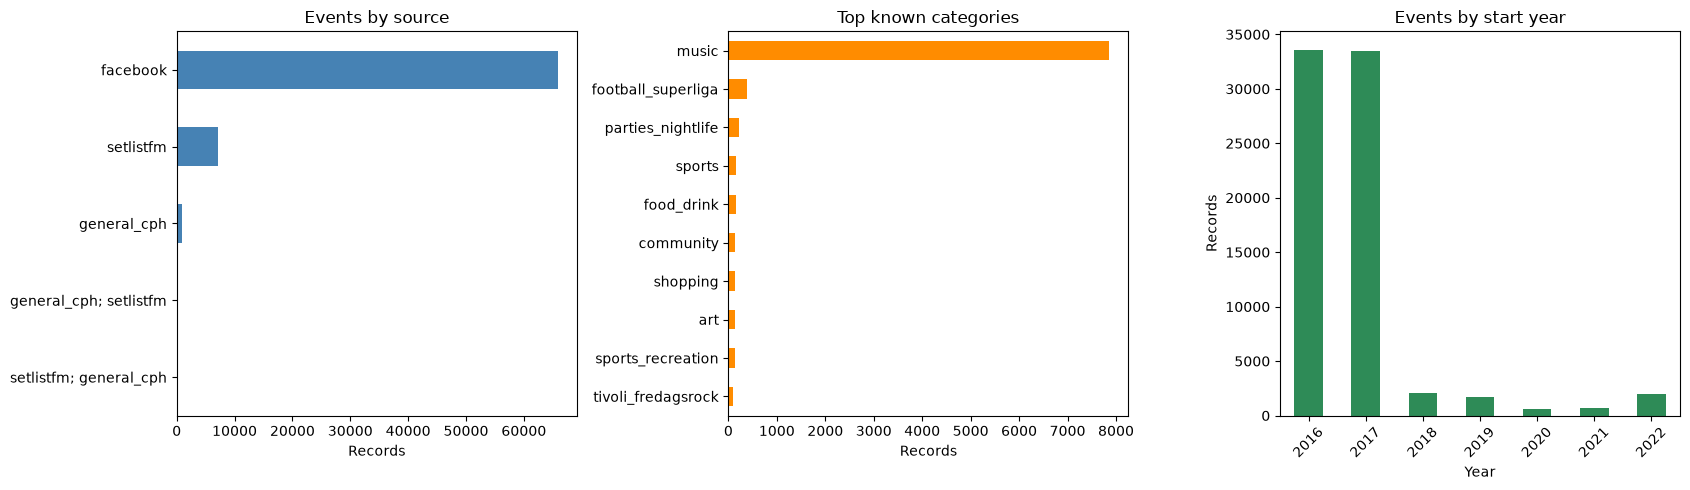

In [42]:
# Plot event counts by source, category, and start year.
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

source_counts.sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set(title="Events by source", xlabel="Records", ylabel="")

known_categories = analysis_events_df["event_category"].dropna().value_counts().head(10).sort_values()
if known_categories.empty:
    axes[1].text(0.5, 0.5, "No categories available", ha="center", va="center", transform=axes[1].transAxes)
else:
    known_categories.plot.barh(ax=axes[1], color="darkorange")
axes[1].set(title="Top known categories", xlabel="Records", ylabel="")

valid_year_counts = analysis_events_df["start_date"].dropna().dt.year.value_counts().sort_index()
if valid_year_counts.empty:
    axes[2].text(0.5, 0.5, "No valid start dates", ha="center", va="center", transform=axes[2].transAxes)
else:
    valid_year_counts.plot.bar(ax=axes[2], color="seagreen")
axes[2].set(title="Events by start year", xlabel="Year", ylabel="Records")
axes[2].tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()


### Venue and attendance distributions

Venue counts show which named venues occur most often. Attendance is highly right-skewed, so the histogram uses `log10(attendance + 1)`; its tick labels are converted back to attendance counts for readability.

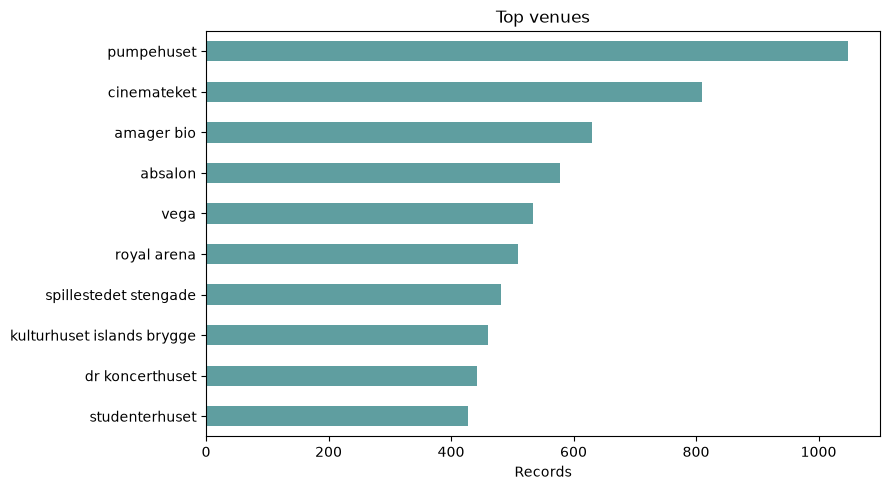

Attendance values available: 66,318


,estimated_attendance
count,66318.000000
mean,304.425133
std,3180.331873
min,0.000000
25%,20.000000
50%,50.000000
75%,134.000000
max,300000.000000


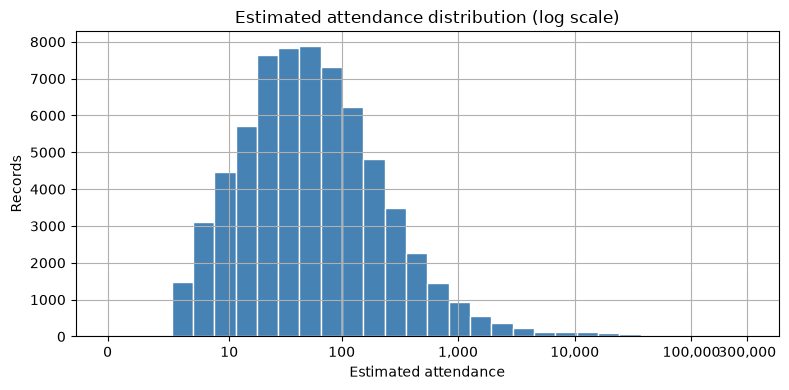

In [43]:
# Show the most frequent venues and summarize estimated attendance.
venue_counts = analysis_events_df["venue_name"].dropna().value_counts().head(10).sort_values()
if venue_counts.empty:
    print("No named venues available.")
else:
    fig, ax = plt.subplots(figsize=(9, 5))
    venue_counts.plot.barh(ax=ax, color="cadetblue")
    ax.set(title="Top venues", xlabel="Records", ylabel="")
    fig.tight_layout()
    plt.show()

attendance_values = pd.to_numeric(
    analysis_events_df["estimated_attendance"], errors="coerce"
).dropna()
if attendance_values.empty:
    print("No estimated attendance values available.")
else:
    print(f"Attendance values available: {len(attendance_values):,}")
    display(attendance_values.describe().to_frame("estimated_attendance"))

    log_attendance = np.log10(attendance_values.clip(lower=0) + 1)
    fig, ax = plt.subplots(figsize=(8, 4))
    log_attendance.hist(bins=30, ax=ax, color="steelblue", edgecolor="white")
    tick_values = np.array([0, 10, 100, 1_000, 10_000, 100_000, 300_000])
    ax.set_xticks(np.log10(tick_values + 1), [f"{value:,}" for value in tick_values])
    ax.set(title="Estimated attendance distribution (log scale)", xlabel="Estimated attendance", ylabel="Records")
    fig.tight_layout()
    plt.show()


## Cross-source duplicate review and consolidation

The next steps identify records that may describe the same event across sources. Candidate pairs must have the same known date and venue, come from different sources, and have event names with a similarity score of at least 0.75. Names are normalized before comparison, so differences in capitalization and punctuation matter less.

The following cell merges these candidates and exact normalized-name matches when their locations agree. It prefers records with coordinates and combines available fields while retaining alternate names and source provenance. These matches are heuristic, so review `merged_groups_df` before treating every merged pair as a confirmed duplicate; events with the same name on different dates remain separate.


In [ ]:
# Find exact and likely duplicate event records across different sources.
import re
from difflib import SequenceMatcher

if "special_events_source_df" not in globals():
    special_events_source_df = special_events_df.copy()


def normalize_event_text(value):
    if pd.isna(value):
        return ""
    text = str(value).casefold()
    text = re.sub(r"[^a-z0-9]+", " ", text)
    return re.sub(r"\s+", " ", text).strip()


comparison_df = special_events_source_df[["event_id", "source", "start_date", "venue_name", "event_category"]].copy()
comparison_df["_row_id"] = range(len(comparison_df))
comparison_df["event_label"] = comparison_df["event_id"].fillna("unknown")
comparison_df["event_name_norm"] = comparison_df["event_label"].map(normalize_event_text)
comparison_df["date_norm"] = pd.to_datetime(comparison_df["start_date"], errors="coerce").dt.strftime("%Y-%m-%d")
comparison_df["venue_norm"] = comparison_df["venue_name"].fillna("").map(normalize_event_text)

# Compare only records with a known date and venue, avoiding huge matches on blank values.
comparison_candidates = comparison_df.loc[
    comparison_df["date_norm"].notna() & comparison_df["venue_norm"].ne("")
]
event_pairs = comparison_candidates.merge(
    comparison_candidates,
    on=["date_norm", "venue_norm"],
    how="inner",
    suffixes=("_a", "_b"),
)
event_pairs = event_pairs.loc[
    (event_pairs["_row_id_a"] < event_pairs["_row_id_b"])
    & (event_pairs["source_a"] != event_pairs["source_b"])
].copy()
event_pairs["name_similarity"] = event_pairs.apply(
    lambda row: SequenceMatcher(
        None, row["event_name_norm_a"], row["event_name_norm_b"]
    ).ratio(),
    axis=1,
)

likely_duplicates = event_pairs.loc[
    event_pairs["name_similarity"].ge(0.75),
    ["_row_id_a", "_row_id_b", "event_label_a", "source_a", "event_label_b", "source_b",
     "date_norm", "venue_norm", "name_similarity"],
].sort_values(["date_norm", "name_similarity"], ascending=[True, False])

print(f"Exact or likely cross-source duplicate candidates: {len(likely_duplicates):,}")
display(likely_duplicates.head(5))

exact_name_duplicates = likely_duplicates.loc[
    likely_duplicates["event_label_a"].map(normalize_event_text)
    == likely_duplicates["event_label_b"].map(normalize_event_text)
].copy()
print(f"Exact normalized-name matches: {len(exact_name_duplicates):,}")


Exact or likely cross-source duplicate candidates: 14


,_row_id_a,_row_id_b,event_label_a,source_a,event_label_b,source_b,date_norm,venue_norm,name_similarity
84440,65841,66946,dizzy mizz lizzy & d-a-d,general_cph,dizzy mizz lizzy @ royal arena,setlistfm,2017-02-17,royal arena,0.760000
84469,65859,67108,dave matthews & tim reynolds,general_cph,dave matthews & tim reynolds @ royal arena,setlistfm,2017-03-29,royal arena,0.812500
84617,65975,67983,nick cave & the bad seeds,general_cph,nick cave & the bad seeds @ royal arena,setlistfm,2017-10-20,royal arena,0.793103
84644,65993,68185,five finger death punch & in flames,general_cph,five finger death punch @ royal arena,setlistfm,2017-11-20,royal arena,0.764706
84648,65994,68197,queen + adam lambert,general_cph,queen + adam lambert @ royal arena,setlistfm,2017-11-22,royal arena,0.750000
85055,66306,71030,eros ramazzotti,general_cph,eros ramazzotti @ kb hallen,setlistfm,2019-10-27,kb hallen,0.750000
85114,66347,71346,magtens korridorer,general_cph,magtens korridorer @ kb hallen,setlistfm,2019-12-28,kb hallen,0.782609
85137,66356,71369,five finger death punch,general_cph,five finger death punch @ royal arena,setlistfm,2020-01-24,royal arena,0.793103
85479,66661,72414,the war on drugs,general_cph,the war on drugs @ kb hallen,setlistfm,2022-03-30,kb hallen,0.761905
85482,66662,72420,the war on drugs,general_cph,the war on drugs @ kb hallen,setlistfm,2022-03-31,kb hallen,0.761905


Exact normalized-name matches: 0


In [29]:
# Merge exact name/date duplicates and the likely matches identified above.
from math import asin, cos, radians, sin, sqrt

special_events_before_dedup_df = special_events_source_df.copy().reset_index(drop=True)
row_count = len(special_events_before_dedup_df)
parent = list(range(row_count))


def find_root(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index


def union_rows(index_a, index_b):
    root_a, root_b = find_root(index_a), find_root(index_b)
    if root_a != root_b:
        parent[root_b] = root_a


def same_location(row_a, row_b):
    venue_a = normalize_event_text(row_a.get("venue_name"))
    venue_b = normalize_event_text(row_b.get("venue_name"))
    if venue_a and venue_b:
        return venue_a == venue_b
    coordinates = [row_a.get("latitude"), row_a.get("longitude"), row_b.get("latitude"), row_b.get("longitude")]
    if any(pd.isna(value) for value in coordinates):
        return False
    lat_a, lon_a, lat_b, lon_b = map(radians, map(float, coordinates))
    delta_lat, delta_lon = lat_b - lat_a, lon_b - lon_a
    distance = 2 * 6_371_000 * asin(sqrt(
        sin(delta_lat / 2) ** 2
        + cos(lat_a) * cos(lat_b) * sin(delta_lon / 2) ** 2
    ))
    return distance <= 150


candidate_pairs = {
    (int(row["_row_id_a"]), int(row["_row_id_b"]))
    for _, row in likely_duplicates.iterrows()
}

# Also match exact normalized names on the same date when locations agree.
exact_match_rows = comparison_df.loc[
    comparison_df["date_norm"].notna() & comparison_df["event_name_norm"].ne("")
]
for _, duplicate_group in exact_match_rows.groupby(["date_norm", "event_name_norm"], sort=False):
    indices = duplicate_group["_row_id"].tolist()
    for position, index_a in enumerate(indices):
        for index_b in indices[position + 1:]:
            if special_events_before_dedup_df.loc[index_a, "source"] != special_events_before_dedup_df.loc[index_b, "source"]:
                candidate_pairs.add((min(index_a, index_b), max(index_a, index_b)))

for index_a, index_b in candidate_pairs:
    if same_location(special_events_before_dedup_df.loc[index_a], special_events_before_dedup_df.loc[index_b]):
        union_rows(index_a, index_b)

groups = {}
for index in range(row_count):
    groups.setdefault(find_root(index), []).append(index)


def is_missing(value):
    if value is None or value is pd.NA:
        return True
    if isinstance(value, (list, tuple, set, dict)):
        return len(value) == 0
    result = pd.isna(value)
    return bool(result) if isinstance(result, (bool, np.bool_)) else False


def row_quality(row):
    has_coordinates = not is_missing(row.get("latitude")) and not is_missing(row.get("longitude"))
    known_values = sum(not is_missing(value) for value in row)
    return has_coordinates, known_values


records = special_events_before_dedup_df.to_dict("records")
removed_indices = set()
for indices in groups.values():
    if len(indices) < 2:
        continue
    ranked = sorted(
        (special_events_before_dedup_df.loc[index] for index in indices),
        key=row_quality,
        reverse=True,
    )
    merged = ranked[0].to_dict()
    for column in special_events_before_dedup_df.columns:
        if column in {"event_id", "source"}:
            continue
        values = [row[column] for row in ranked if not is_missing(row[column])]
        if not values:
            continue
        if all(isinstance(value, (list, tuple)) for value in values):
            combined = []
            for value in values:
                combined.extend(item for item in value if item not in combined)
            merged[column] = combined
        else:
            merged[column] = values[0]

    names = list(dict.fromkeys(row["event_id"] for row in ranked if not is_missing(row["event_id"])))
    merged["event_id"] = max(names, key=lambda name: len(normalize_event_text(name))) if names else pd.NA
    merged["alternate_event_names"] = names
    merged["source"] = "; ".join(dict.fromkeys(str(row["source"]) for row in ranked if not is_missing(row["source"])))
    merged["merged_record_count"] = len(indices)
    merged["attendance_observations"] = [
        {"source": str(row["source"]), "estimated_attendance": row["estimated_attendance"]}
        for row in ranked
        if "estimated_attendance" in row and not is_missing(row["estimated_attendance"])
    ]
    records[indices[0]] = merged
    removed_indices.update(indices[1:])

special_events_deduplicated_df = pd.DataFrame(
    [record for index, record in enumerate(records) if index not in removed_indices]
)
merged_groups_df = special_events_deduplicated_df.loc[
    special_events_deduplicated_df["merged_record_count"].gt(1),
    ["event_id", "alternate_event_names", "start_date", "venue_name", "source",
     "merged_record_count", "estimated_attendance", "attendance_observations"],
].copy()

print(
    f"Reduced {len(special_events_before_dedup_df):,} records to "
    f"{len(special_events_deduplicated_df):,}; merged {len(merged_groups_df):,} groups."
)
display(merged_groups_df.head(30))
special_events_df = special_events_deduplicated_df


Reduced 74,062 records to 74,048; merged 14 groups.


,event_id,alternate_event_names,start_date,venue_name,source,merged_record_count,estimated_attendance,attendance_observations
65841,dizzy mizz lizzy @ royal arena,"[dizzy mizz lizzy & d-a-d, dizzy mizz lizzy @ ...",2017-02-17,royal arena,general_cph; setlistfm,2.0,NaN,[]
65859,dave matthews & tim reynolds @ royal arena,"[dave matthews & tim reynolds, dave matthews &...",2017-03-29,royal arena,general_cph; setlistfm,2.0,NaN,[]
65975,nick cave & the bad seeds @ royal arena,"[nick cave & the bad seeds, nick cave & the ba...",2017-10-20,royal arena,general_cph; setlistfm,2.0,NaN,[]
65993,five finger death punch @ royal arena,"[five finger death punch & in flames, five fin...",2017-11-20,royal arena,general_cph; setlistfm,2.0,NaN,[]
65994,queen + adam lambert @ royal arena,"[queen + adam lambert, queen + adam lambert @ ...",2017-11-22,royal arena,general_cph; setlistfm,2.0,NaN,[]
66306,eros ramazzotti @ kb hallen,"[eros ramazzotti, eros ramazzotti @ kb hallen]",2019-10-27,kb hallen,general_cph; setlistfm,2.0,NaN,[]
66347,magtens korridorer @ kb hallen,"[magtens korridorer, magtens korridorer @ kb h...",2019-12-28,kb hallen,general_cph; setlistfm,2.0,NaN,[]
66356,five finger death punch @ royal arena,"[five finger death punch, five finger death pu...",2020-01-24,royal arena,general_cph; setlistfm,2.0,NaN,[]
66661,the war on drugs @ kb hallen,"[the war on drugs, the war on drugs @ kb hallen]",2022-03-30,kb hallen,general_cph; setlistfm,2.0,NaN,[]
66662,the war on drugs @ kb hallen,"[the war on drugs, the war on drugs @ kb hallen]",2022-03-31,kb hallen,general_cph; setlistfm,2.0,NaN,[]


# Final Analysis

This section first reports quality and coverage for the consolidated table. It then creates a separate cleaned dataset by removing records without both coordinates and fields that are effectively 100% missing, and recalculates completeness for that cleaned dataset.

In [44]:
# Overall size, missingness, and source-level coverage before final filtering.
final_events_df = special_events_df.copy()
row_count = len(final_events_df)

print(f"Final event records: {row_count:,}")
print(f"Columns: {len(final_events_df.columns)}")
print(f"Distinct non-missing event names/IDs: {final_events_df['event_id'].nunique():,}")

missing_counts = final_events_df.isna().sum()
for column in ["nearest_stations", "nearest_stop_ids", "nearest_stop_distances_m"]:
    if column in final_events_df:
        missing_counts.loc[column] += final_events_df[column].map(
            lambda value: isinstance(value, (list, tuple)) and len(value) == 0
        ).sum()
missing_report_df = pd.DataFrame({
    "missing_count": missing_counts.astype(int),
    "missing_percent": (missing_counts / max(row_count, 1) * 100).round(2),
}).sort_values("missing_percent", ascending=False)
print("Missing values before filtering:")
display(missing_report_df)

coverage_columns = [
    column for column in [
        "start_date", "start_time", "end_date", "end_time", "venue_name",
        "latitude", "longitude", "estimated_attendance", "event_category",
    ]
    if column in final_events_df.columns
]
source_coverage_df = final_events_df.groupby("source", dropna=False).agg(
    records=("event_id", "size"),
    **{
        f"{column}_available": (column, lambda values: values.notna().sum())
        for column in coverage_columns
    },
)
print("Field coverage by source:")
display(source_coverage_df)


Final event records: 74,048
Columns: 17
Distinct non-missing event names/IDs: 72,862
Missing values before filtering:


,missing_count,missing_percent
attendance_observations,74034,99.98
merged_record_count,74034,99.98
alternate_event_names,74034,99.98
event_category,63341,85.54
end_time,17377,23.47
end_date,16396,22.14
estimated_attendance,7730,10.44
start_time,7567,10.22
longitude,743,1.00
latitude,743,1.00


Field coverage by source:


,records,start_date_available,start_time_available,end_date_available,end_time_available,venue_name_available,latitude_available,longitude_available,estimated_attendance_available,event_category_available
source,,,,,,,,,,
facebook,65836,65836,65836,56646,56646,65835,65836,65836,65836,2495
general_cph,992,992,575,992,0,992,926,926,471,992
general_cph; setlistfm,13,13,7,13,1,13,13,13,0,13
setlistfm,7206,7206,62,0,23,7194,6529,6529,11,7206
setlistfm; general_cph,1,1,1,1,1,1,1,1,0,1


### Quality checks and distributions

Check date and coordinate validity, repeated names, attendance statistics, and category coverage on the full consolidated table before filtering.

In [45]:
# Summarize invalid dates/coordinates, attendance, and category coverage.
start_dates = pd.to_datetime(final_events_df["start_date"], errors="coerce")
end_dates = pd.to_datetime(final_events_df["end_date"], errors="coerce")
latitude = pd.to_numeric(final_events_df["latitude"], errors="coerce")
longitude = pd.to_numeric(final_events_df["longitude"], errors="coerce")

quality_summary = pd.Series({
    "missing event name/ID": final_events_df["event_id"].isna().sum(),
    "missing start date": start_dates.isna().sum(),
    "end date before start date": (
        end_dates.lt(start_dates) & end_dates.notna() & start_dates.notna()
    ).sum(),
    "incomplete coordinate pair": latitude.isna().ne(longitude.isna()).sum(),
    "invalid latitude/longitude": (
        (latitude.notna() & ~latitude.between(-90, 90))
        | (longitude.notna() & ~longitude.between(-180, 180))
    ).sum(),
    "missing estimated attendance": final_events_df["estimated_attendance"].isna().sum(),
    "reused event names/IDs (may be distinct events)": final_events_df["event_id"].duplicated(keep=False).sum(),
}, name="record_count")
display(quality_summary.to_frame())

attendance_values = pd.to_numeric(final_events_df["estimated_attendance"], errors="coerce")
if attendance_values.notna().any():
    display(attendance_values.describe().to_frame("estimated_attendance"))

missing_category_count = final_events_df["event_category"].isna().sum()
print(
    f"Events with no category: {missing_category_count:,} "
    f"({missing_category_count / max(row_count, 1):.1%})"
)
display(final_events_df["event_category"].value_counts().head(15).rename("records").to_frame())


,record_count
missing event name/ID,0
missing start date,0
end date before start date,0
incomplete coordinate pair,0
invalid latitude/longitude,0
missing estimated attendance,7730
reused event names/IDs (may be distinct events),1864


,estimated_attendance
count,66318.000000
mean,304.425133
std,3180.331873
min,0.000000
25%,20.000000
50%,50.000000
75%,134.000000
max,300000.000000


Events with no category: 63,341 (85.5%)


,records
event_category,
music,7861
football_superliga,391
parties_nightlife,222
sports,154
food_drink,149
community,145
shopping,130
art,129
sports_recreation,127


### Final analysis plots

Visual summaries of missingness in event fields, event counts by year and category, and the estimated-attendance distribution. Attendance is shown on a log scale because the distribution is strongly right-skewed.

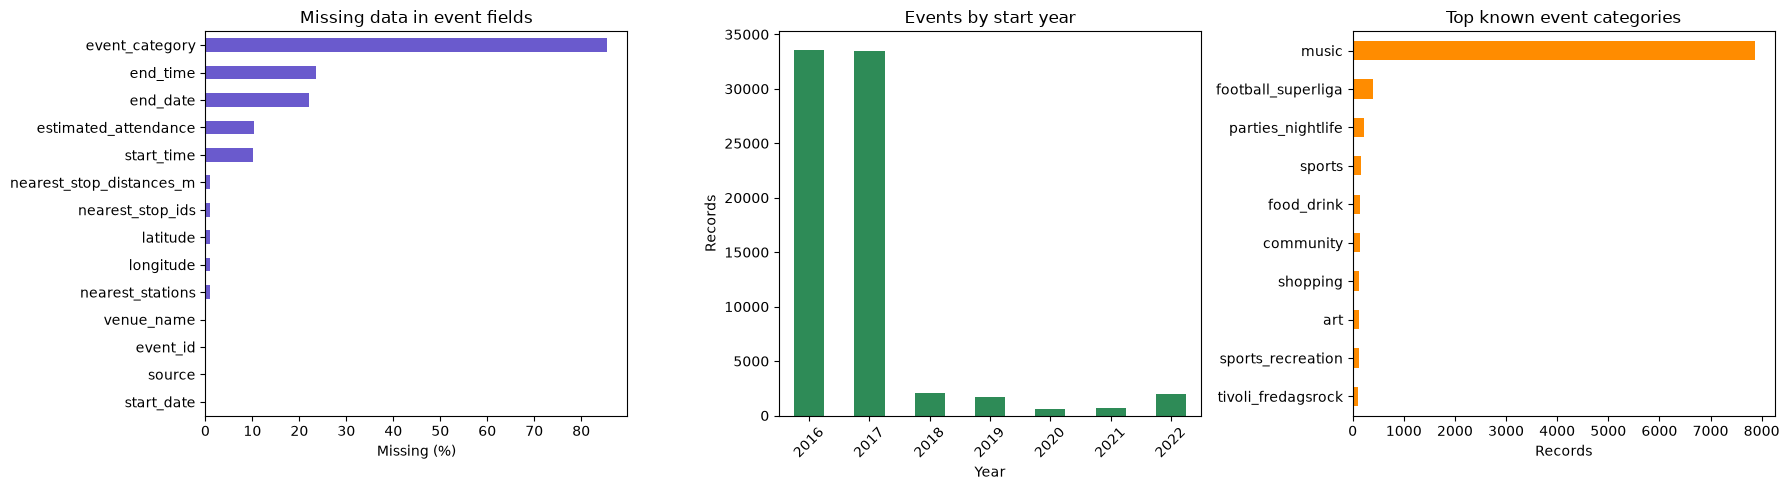

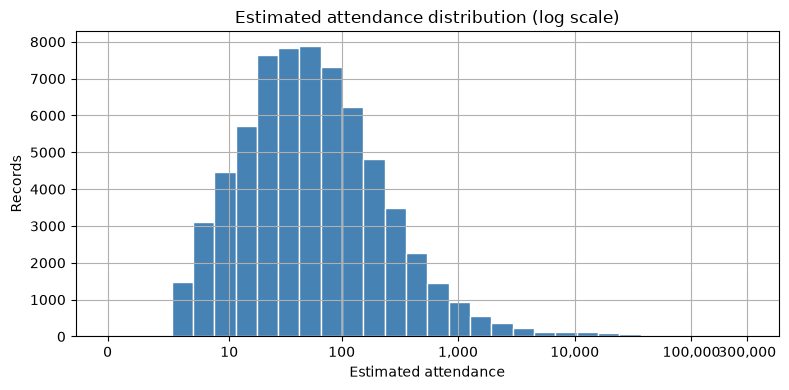

In [46]:
# Plot missingness, event counts by year, and known event categories.
audit_columns = {"alternate_event_names", "merged_record_count", "attendance_observations"}
core_missing_report = missing_report_df.drop(
    index=list(audit_columns.intersection(missing_report_df.index))
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
core_missing_report["missing_percent"].sort_values().plot.barh(
    ax=axes[0], color="slateblue"
)
axes[0].set(title="Missing data in event fields", xlabel="Missing (%)", ylabel="")

valid_years = start_dates.dropna().dt.year.value_counts().sort_index()
if valid_years.empty:
    axes[1].text(0.5, 0.5, "No valid start dates", ha="center", va="center", transform=axes[1].transAxes)
else:
    valid_years.plot.bar(ax=axes[1], color="seagreen")
axes[1].set(title="Events by start year", xlabel="Year", ylabel="Records")
axes[1].tick_params(axis="x", rotation=45)

top_categories = final_events_df["event_category"].dropna().value_counts().head(10).sort_values()
if top_categories.empty:
    axes[2].text(0.5, 0.5, "No categories available", ha="center", va="center", transform=axes[2].transAxes)
else:
    top_categories.plot.barh(ax=axes[2], color="darkorange")
axes[2].set(title="Top known event categories", xlabel="Records", ylabel="")
fig.tight_layout()
plt.show()

attendance_values = pd.to_numeric(final_events_df["estimated_attendance"], errors="coerce")
if attendance_values.notna().any():
    log_attendance = np.log10(attendance_values.dropna().clip(lower=0) + 1)
    fig, ax = plt.subplots(figsize=(8, 4))
    log_attendance.hist(bins=30, ax=ax, color="steelblue", edgecolor="white")
    tick_values = np.array([0, 10, 100, 1_000, 10_000, 100_000, 300_000])
    ax.set_xticks(np.log10(tick_values + 1), [f"{value:,}" for value in tick_values])
    ax.set(title="Estimated attendance distribution (log scale)", xlabel="Estimated attendance", ylabel="Records")
    fig.tight_layout()
    plt.show()


In [47]:
# Create a cleaned copy; keep the full special_events_df available for comparison.
special_events_clean_df = special_events_df.copy()
initial_row_count = len(special_events_clean_df)

has_complete_coordinates = (
    special_events_clean_df["latitude"].notna()
    & special_events_clean_df["longitude"].notna()
)
special_events_clean_df = special_events_clean_df.loc[has_complete_coordinates].copy()
removed_coordinate_rows = initial_row_count - len(special_events_clean_df)

# Drop columns that display as 100.0% missing when percentages are rounded to one decimal.
missing_percent_before_drop = special_events_clean_df.isna().mean().mul(100).round(1)
fully_missing_columns = missing_percent_before_drop.index[
    missing_percent_before_drop.eq(100.0)
].tolist()
special_events_clean_df = special_events_clean_df.drop(columns=fully_missing_columns)

print(f"Rows before coordinate filtering: {initial_row_count:,}")
print(f"Rows dropped for missing latitude or longitude: {removed_coordinate_rows:,}")
print(f"Rows after coordinate filtering: {len(special_events_clean_df):,}")
print(f"Columns dropped at 100.0% missing: {fully_missing_columns}")


Rows before coordinate filtering: 74,048
Rows dropped for missing latitude or longitude: 743
Rows after coordinate filtering: 73,305
Columns dropped at 100.0% missing: ['alternate_event_names', 'merged_record_count', 'attendance_observations']


### Completeness after filtering

Recalculate null counts and percentages after removing coordinate-incomplete rows and all-missing audit columns. Empty station/stop lists are counted as unavailable alongside nulls.

In [48]:
# Recalculate null counts and percentages for the cleaned table.
cleaned_missing_counts = special_events_clean_df.isna().sum()
for column in ["nearest_stations", "nearest_stop_ids", "nearest_stop_distances_m"]:
    if column in special_events_clean_df:
        cleaned_missing_counts.loc[column] += special_events_clean_df[column].map(
            lambda value: isinstance(value, (list, tuple)) and len(value) == 0
        ).sum()

cleaned_missing_report_df = pd.DataFrame({
    "missing_count": cleaned_missing_counts.astype(int),
    "missing_percent": (
        cleaned_missing_counts / max(len(special_events_clean_df), 1) * 100
    ).round(2),
}).sort_values(["missing_percent", "missing_count"], ascending=False)
display(cleaned_missing_report_df)

print("Cleaned records by source:")
display(special_events_clean_df["source"].value_counts(dropna=False).rename("records").to_frame())

cleaned_years = pd.to_datetime(
    special_events_clean_df["start_date"], errors="coerce"
).dt.year.value_counts().sort_index()
print("Cleaned records by start year:")
display(cleaned_years.rename("records").to_frame())


,missing_count,missing_percent
event_category,63341,86.41
end_time,16635,22.69
end_date,15719,21.44
estimated_attendance,7024,9.58
start_time,6853,9.35
venue_name,1,0.00
event_id,0,0.00
start_date,0,0.00
latitude,0,0.00
longitude,0,0.00


Cleaned records by source:


,records
source,
facebook,65836
setlistfm,6529
general_cph,926
general_cph; setlistfm,13
setlistfm; general_cph,1


Cleaned records by start year:


,records
start_date,
2016,33600
2017,33314
2018,1817
2019,1593
2020,544
2021,607
2022,1830


### Remaining missingness

This plot excludes fields that were removed because they were 100% missing and shows only fields with remaining unavailable values.

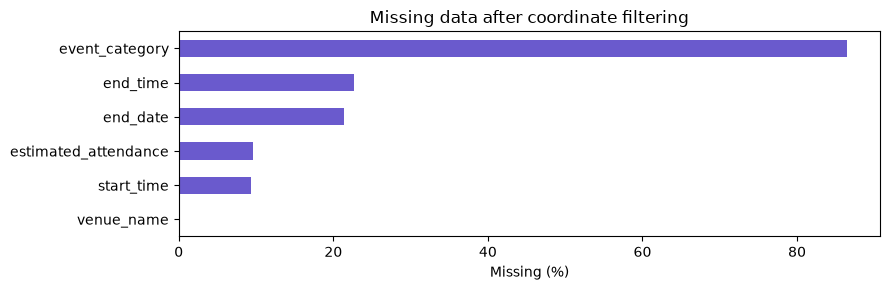

In [49]:
missing_to_plot = cleaned_missing_report_df.loc[
    cleaned_missing_report_df["missing_count"].gt(0), "missing_percent"
].sort_values()
if not missing_to_plot.empty:
    fig, ax = plt.subplots(figsize=(9, max(3, len(missing_to_plot) * 0.35)))
    missing_to_plot.plot.barh(ax=ax, color="slateblue")
    ax.set(title="Missing data after coordinate filtering", xlabel="Missing (%)", ylabel="")
    fig.tight_layout()
    plt.show()
else:
    print("No missing values remain in the cleaned dataset.")


In [32]:
special_events_clean_df.head(10)

,event_id,start_date,end_date,start_time,end_time,venue_name,latitude,longitude,estimated_attendance,event_category,nearest_stations,source,nearest_stop_ids,nearest_stop_distances_m
0,149546672171110,2016-11-05,2016-11-05,20:00:00,23:00:00,copenhagen,55.676100,12.568300,33.0,NaN,"[Rådhuspladsen St. (Metro), Rådhuspladsen St. ...",facebook,"[000008603331, 000000047029, 000000047229, 000...","[43.8, 64.0, 99.8, 113.3, 158.3]"
1,498195710570724,2017-05-04,2017-05-04,17:45:00,18:25:00,"nationalmuseet (aktiviteter, tilbud m.m.)",55.674490,12.574680,67.0,NaN,"[Stormbroen, Nationalmuseet (Vindebrogade), St...",facebook,"[000000000673, 000000000720, 000000000808, 000...","[179.3, 198.7, 205.2, 245.9, 252.2]"
2,207324133080663,2017-03-15,2017-03-15,17:00:00,19:00:00,bitlab - copenhagen business school,55.680420,12.524760,19.0,NaN,"[Solvej (Howitzvej), Fasanvej St. (Metro), Fas...",facebook,"[000000048844, 000008603304, 000000001671, 000...","[22.8, 173.5, 179.6, 183.4, 194.3]"
3,144194456022010,2016-09-09,2016-09-10,14:00:00,03:00:00,frebar,55.702800,12.561380,680.0,NaN,"[Universitetsparken (Jagtvej), Universitetspar...",facebook,"[000000001125, 000000001086, 000000007192, 000...","[151.0, 186.7, 212.5, 295.9, 324.4]"
4,255578924899334,2017-04-04,2017-04-04,18:00:00,21:15:00,casa latinoamericana denmark,55.659430,12.501080,48.0,NaN,"[Vigerslev Allé St. (Vigerslev Allé), Vigersle...",facebook,"[000000007064, 000008600804, 000000007007, 000...","[139.9, 158.9, 193.1, 236.4, 314.0]"
5,1033681260011742,2016-03-15,NaN,18:15:00,NaN,cinemateket,55.683120,12.578590,56.0,NaN,"[Nørreport St. (Nørre Voldgade), Nørreport St....",facebook,"[000000050460, 000000006584, 000000028329, 000...","[362.1, 388.1, 416.1, 426.0, 427.0]"
6,1711028522516430,2016-04-02,NaN,20:00:00,NaN,dr koncerthuset,55.657730,12.588550,133.0,NaN,"[DR Byen St. (Metro), DR Byen St. (Grønjordsve...",facebook,"[000008603311, 000000027548, 000000000860, 000...","[214.9, 234.1, 257.4, 314.4, 440.6]"
7,1213094235394665,2017-01-26,2017-01-26,18:00:00,20:00:00,det danske filmskuespiller-akademi,55.672530,12.551630,31.0,NaN,"[Frederiksberg Allé (Vesterbrogade), Frederiks...",facebook,"[000000001450, 000000001529, 000000002303, 000...","[35.0, 139.5, 150.4, 176.7, 191.9]"
8,508263452697472,2016-09-20,NaN,19:30:00,NaN,det teologiske fakultet ved københavns univers...,55.662430,12.591030,95.0,NaN,"[Amagerfælled Skole (Njalsgade), Amagerfælled ...",facebook,"[000000000940, 000000000859, 000000000740, 000...","[155.9, 177.7, 257.4, 285.8, 358.6]"
9,1136761586417090,2016-09-23,2016-09-24,21:00:00,00:00:00,spise\bar nr.20,55.686202,12.550957,8.0,NaN,"[Rantzausgade (Griffenfeldsgade), Rantzausgade...",facebook,"[000000001555, 000000001578, 000000054901, 000...","[107.4, 108.2, 125.5, 147.2, 170.6]"


In [35]:
# Save to csv
output_file_path = project_root / "data" /"processed" / "events" / "special_events_clean.csv"
special_events_clean_df.to_csv(output_file_path, index=False)